# SBP verification

Full grid versus limited lines. Default alignment uses the full-grid reference. Edit plot labels below; PNG/PDF exports go to `plots/verification/`.

In [1]:
from pathlib import Path
import numpy as np
from src import sbp_verification as sbp
from src import verification_plots as plots
from src import verification_diagnostics as diagnostics

## 1. Measurement and sampling

In [2]:
DATA_DIR = Path("data/full_bead_pull")
OUTPUT_DIR = Path("outputs/sbp_verification")
LINE_COUNT = 3
Z_SLICE_COUNT = 1
GAP_COUNT = 4
FREQUENCY_INDICES = np.arange(230, 271, 5)
REFERENCE_ALIGNMENT = True
TIME_GATING = True
N_WORKERS = 1
PLOT_ROOT = Path("plots/verification")
FREQUENCY_GHZ = 19.5
FIGURE_DIR = PLOT_ROOT / f"L{LINE_COUNT}_Z{Z_SLICE_COUNT}_G{GAP_COUNT}" / (
    "reference_assisted" if REFERENCE_ALIGNMENT else "line_only"
)

gaps = sbp.discover_gaps(DATA_DIR)
for gap in gaps:
    print(f"Gap {gap.rank}: {gap.name}, acquisition z = {gap.z_min_mm:g}–{gap.z_max_mm:g} mm")

Gap 1: measurement_Al2O3_3mm_2025_09_19_18_59.hdf5, acquisition z = 2–4 mm
Gap 2: measurement_Al2O3_3mm_2025_09_23_17_15.hdf5, acquisition z = 16–18 mm
Gap 3: measurement_Al2O3_3mm_2025_09_23_08_18.hdf5, acquisition z = 22–24 mm
Gap 4: measurement_Al2O3_3mm_2025_09_21_05_54.hdf5, acquisition z = 35–42 mm


## 2. Reconstruct fields

In [3]:
for gap in gaps[:GAP_COUNT]:
    indices = sbp.select_gap_z_ixs(gap, Z_SLICE_COUNT)
    print(f"Gap {gap.rank}: array indices {indices}, acquisition z [mm] = "
          f"{np.asarray(gap.z_positions_m)[list(indices)] * 1e3}")

result = sbp.verify_scan(
    gaps, line_count=LINE_COUNT, z_slice_count=Z_SLICE_COUNT,
    gap_count=GAP_COUNT, frequency_indices=FREQUENCY_INDICES,
    reference_alignment=REFERENCE_ALIGNMENT, time_gating=TIME_GATING,
    n_workers=N_WORKERS,
)
result["metrics"]

Gap 1: array indices (2,), acquisition z [mm] = [4.]
Gap 2: array indices (0,), acquisition z [mm] = [16.]
Gap 3: array indices (2,), acquisition z [mm] = [24.]
Gap 4: array indices (3,), acquisition z [mm] = [38.]


Using backend='thread' with n_workers=1 for fitting 9 tasks.


E-field fit:   0%|          | 0/9 [00:00<?, ?fit/s]

Using backend='thread' with n_workers=1 for fitting 9 tasks.


E-field fit:   0%|          | 0/9 [00:00<?, ?fit/s]

Using backend='thread' with n_workers=1 for fitting 9 tasks.


E-field fit:   0%|          | 0/9 [00:00<?, ?fit/s]

Using backend='thread' with n_workers=1 for fitting 9 tasks.


E-field fit:   0%|          | 0/9 [00:00<?, ?fit/s]

{'line_count': 3,
 'z_slice_count': 1,
 'gap_count': 4,
 'n_reduced_points': 51,
 'n_reduced_z': 4,
 'fit_success_fraction': 1.0,
 'fit_cost_median': 50909.50120207424,
 'fit_cost_p90': 213802.28276386892,
 'et_complex_nrmse': 0.22950395497762938,
 'rel_abs_et_median': 0.18870334466035849,
 'rel_abs_et_p90': 0.46699136599881974,
 'et_complex_nrmse_19_20ghz': 0.22950395497762938,
 'rel_abs_et_median_19_20ghz': 0.18870334466035849,
 'rel_abs_et_p90_19_20ghz': 0.46699136599881974}

In [4]:
example = result["example"]
f_index = int(np.argmin(abs(result["frequencies"] - FREQUENCY_GHZ * 1e9)))

## 3. Selected points

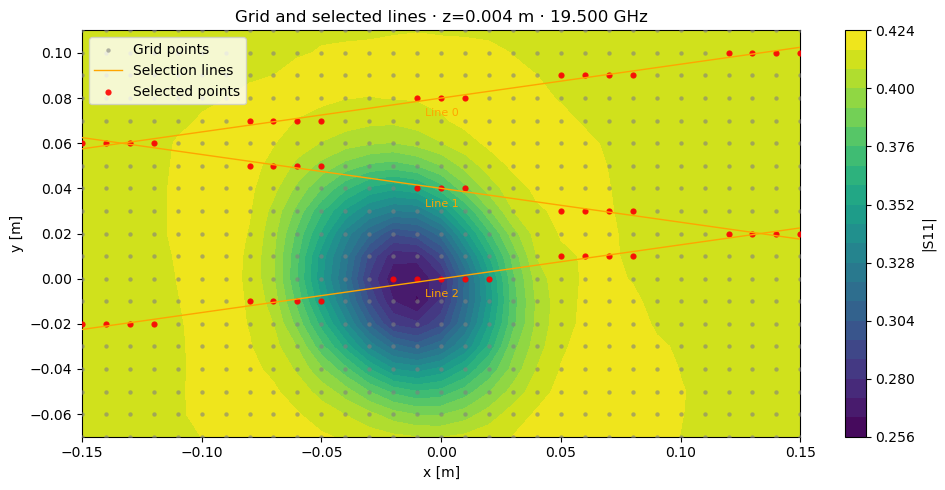

In [5]:
figure, _ = diagnostics.plot_point_selection(
    example,
    z_index=0,
    frequency_index=f_index,
    show_point_ix=False,
    show_line_ix=True,
    title_template='Grid and selected lines · z={z_m:g} m · {frequency_GHz:.3f} GHz',
    x_label='x [m]',
    y_label='y [m]',
    colorbar_label='|S11|',
    grid_label='Grid points',
    lines_label='Selection lines',
    selected_label='Selected points',
    line_label_template='Line {line_index}',
)
plots.present(figure, "point_selection", FIGURE_DIR / "sampling")

## 4. Per-line background and square root

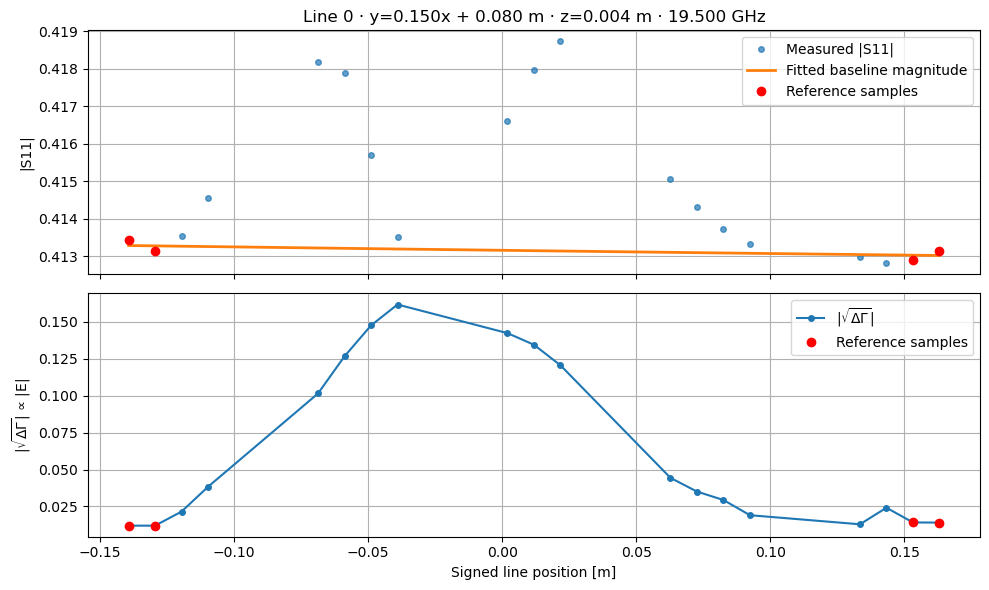

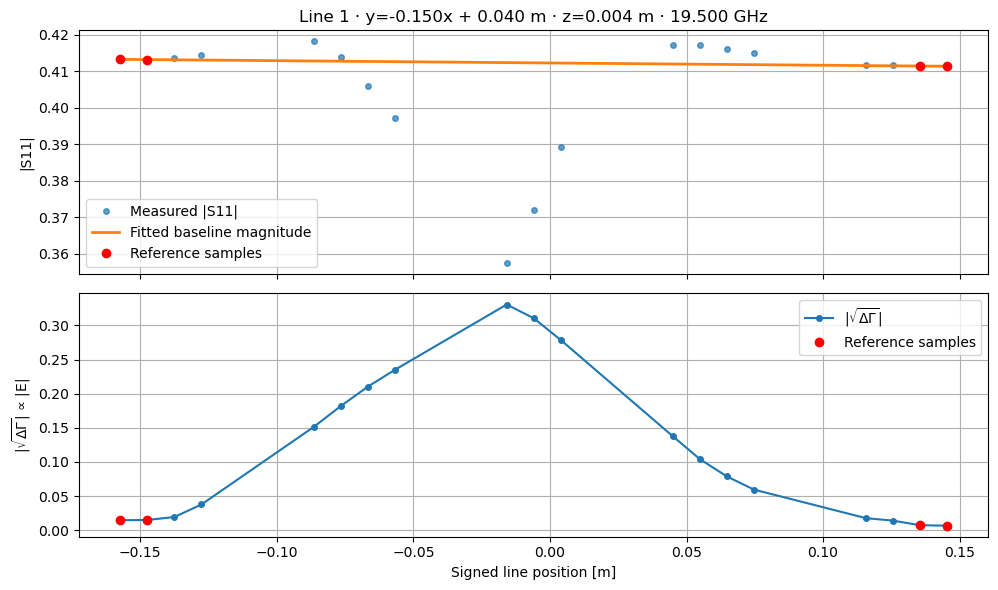

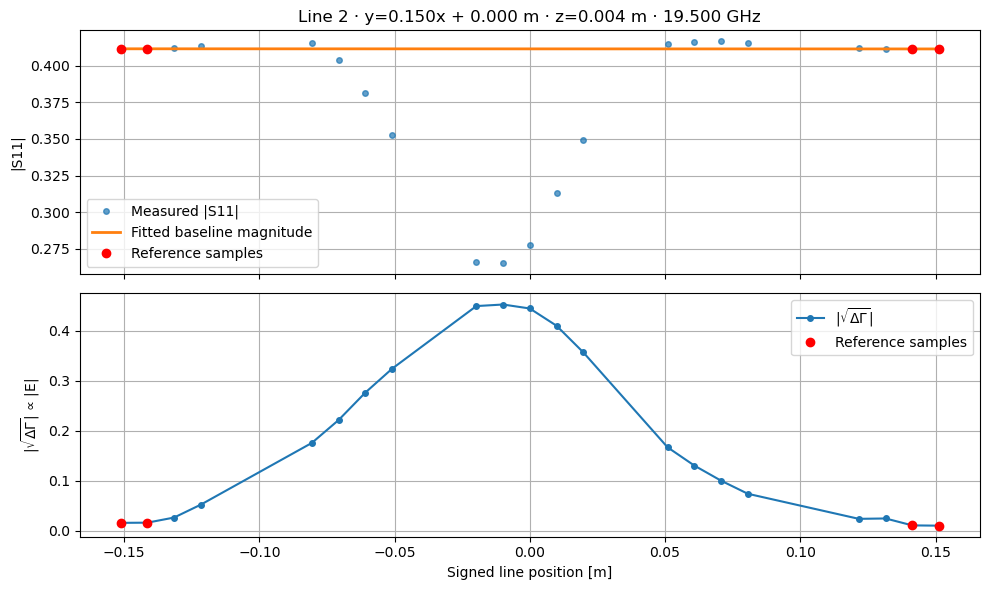

In [6]:
for line_index in range(LINE_COUNT):
    figure, _ = diagnostics.plot_sqrt_Dgamma_line(
        example,
        line_index=line_index,
        z_index=0,
        frequency_index=f_index,
        n_baseline_margin=2,
        title_template='Line {line_index} · y={slope:.3f}x + {intercept:.3f} m · z={z_m:g} m · {frequency_GHz:.3f} GHz',
        x_label='Signed line position [m]',
        reflection_y_label='|S11|',
        field_y_label='$|\\sqrt{\\Delta\\Gamma}|$ ∝ |E|',
        measured_label='Measured |S11|',
        baseline_label='Fitted baseline magnitude',
        reference_label='Reference samples',
        root_label='$|\\sqrt{\\Delta\\Gamma}|$',
    )
    plots.present(figure, f"line_{line_index:02d}", FIGURE_DIR / "preprocessing/background")

## 5. Full-reference alignment

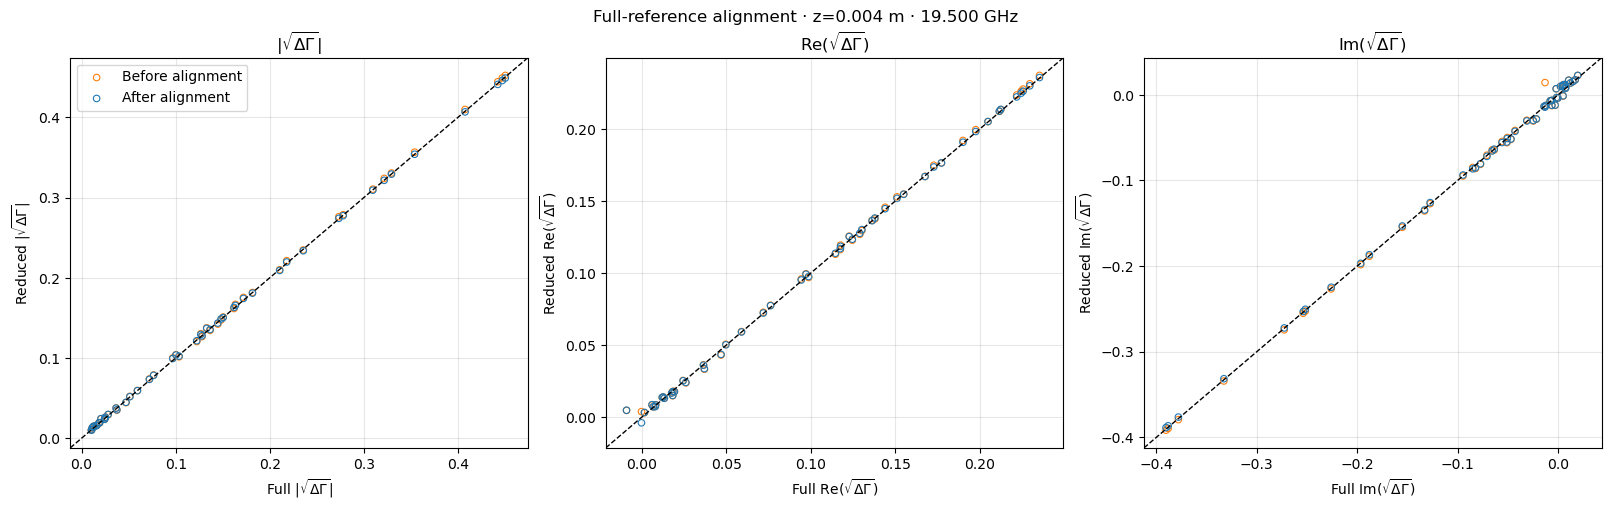

In [7]:
figure, _ = diagnostics.plot_sqrt_dgamma_before_after_correction(
    example,
    z_index=0,
    frequency_index=f_index,
    colors=('tab:orange', 'tab:blue'),
    labels=('Before alignment', 'After alignment'),
    title_template='Full-reference alignment · z={z_m:g} m · {frequency_GHz:.3f} GHz',
    component_labels=('$|\\sqrt{\\Delta\\Gamma}|$', '$\\mathrm{Re}(\\sqrt{\\Delta\\Gamma})$', '$\\mathrm{Im}(\\sqrt{\\Delta\\Gamma})$'),
    x_label_template='Full {component}',
    y_label_template='Reduced {component}',
)
plots.present(figure, "reference_alignment", FIGURE_DIR / "preprocessing")

## 6. Measured and fitted complex fields

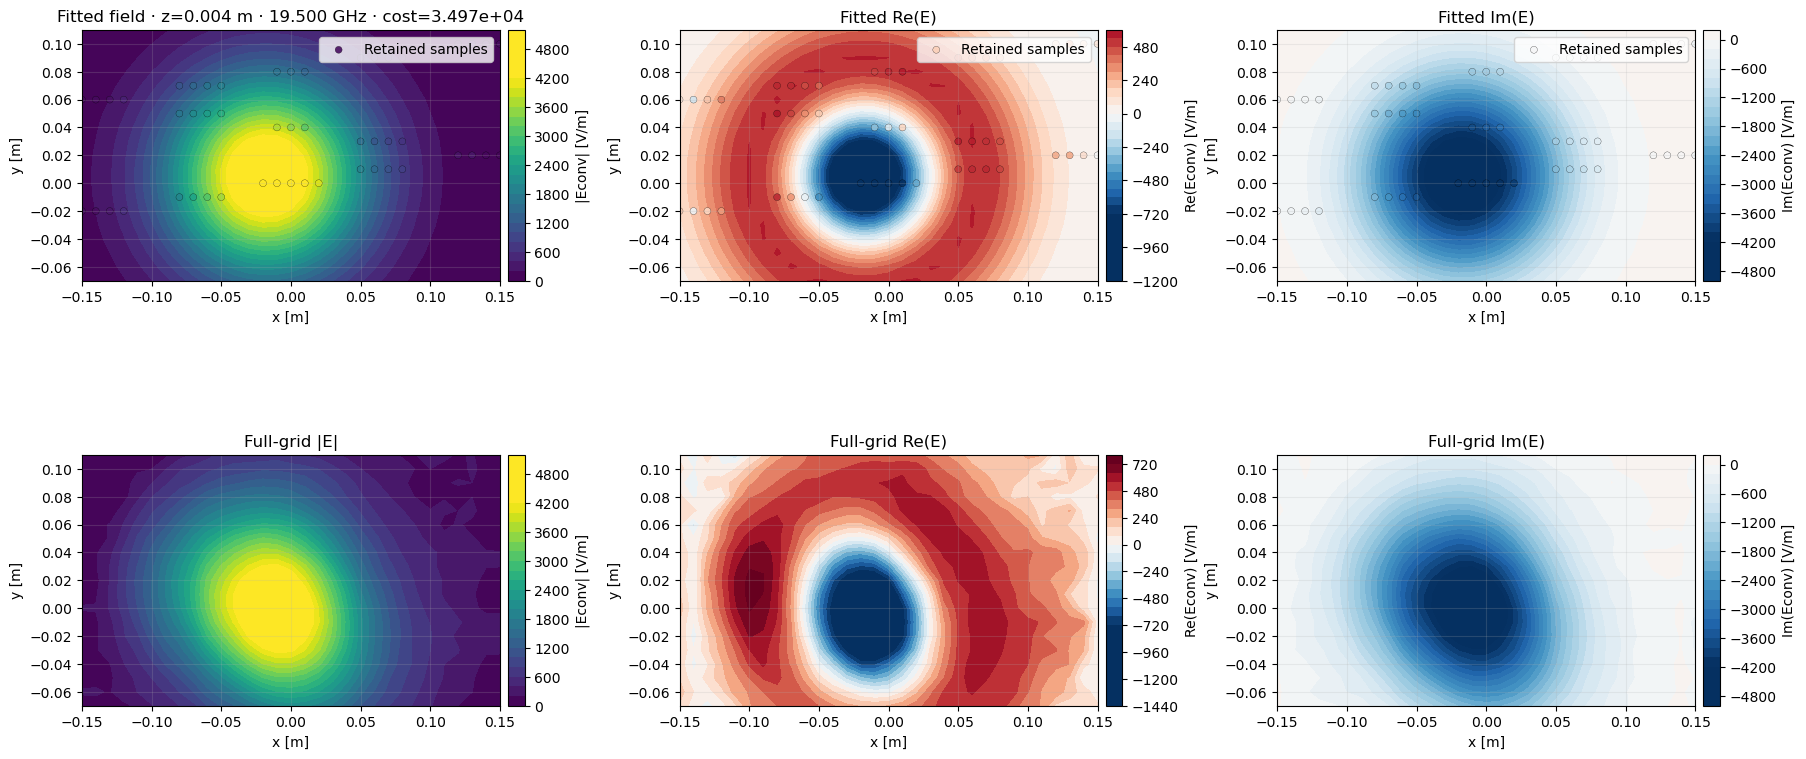

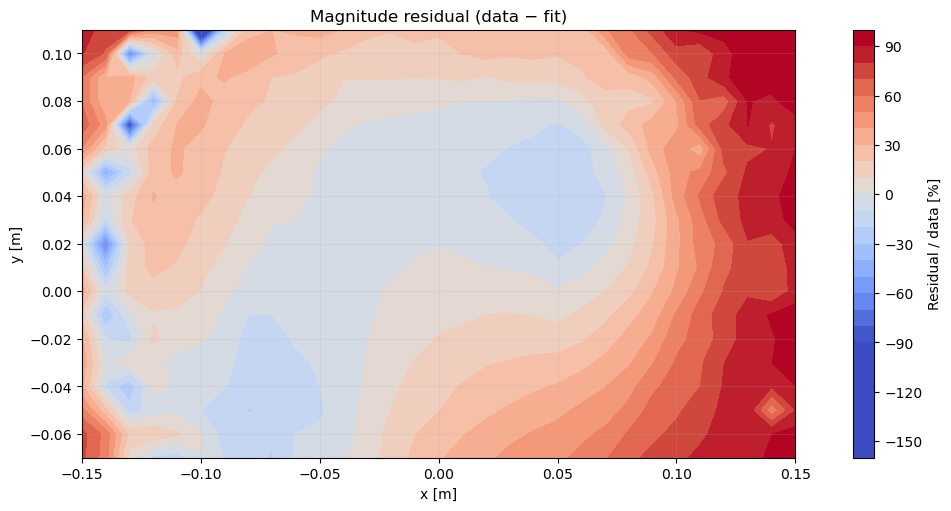

In [8]:
field_figure, _, residual_figure, _ = diagnostics.plot_fitted_efield(
    example,
    z_index=0,
    frequency_index=f_index,
    overlay_points=True,
    title_template='Fitted field · z={z_m:g} m · {frequency_GHz:.3f} GHz · cost={cost:.3e}',
    fitted_real_title='Fitted Re(E)',
    fitted_imaginary_title='Fitted Im(E)',
    data_magnitude_title='Full-grid |E|',
    data_real_title='Full-grid Re(E)',
    data_imaginary_title='Full-grid Im(E)',
    residual_title='Magnitude residual (data − fit)',
    x_label='x [m]',
    y_label='y [m]',
    magnitude_colorbar_label='|Econv| [V/m]',
    real_colorbar_label='Re(Econv) [V/m]',
    imaginary_colorbar_label='Im(Econv) [V/m]',
    residual_colorbar_label='Residual / data [%]',
    samples_label='Retained samples',
)
plots.present(field_figure, "complex_field_comparison", FIGURE_DIR / "fields")
plots.present(residual_figure, "magnitude_residual", FIGURE_DIR / "fields")

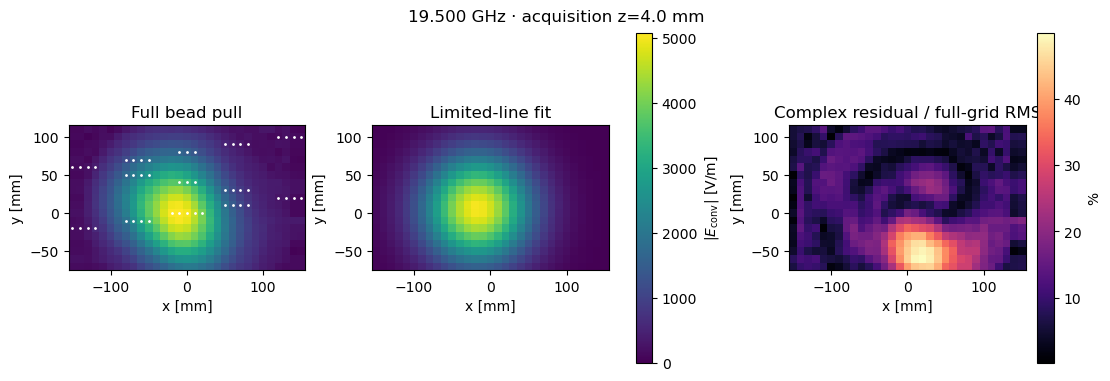

In [9]:
plots.present(
    plots.plot_fields(
        example,
        z_index=0,
        frequency_index=f_index,
        title_template='{frequency_GHz:.3f} GHz · acquisition z={z_mm:.1f} mm',
        full_title='Full bead pull',
        fit_title='Limited-line fit',
        residual_title='Complex residual / full-grid RMS',
        x_label='x [mm]',
        y_label='y [mm]',
        field_colorbar_label='$|E_{\\mathrm{conv}}|$ [V/m]',
        residual_colorbar_label='%',
    ),
    "magnitude_and_complex_residual", FIGURE_DIR / "fields",
)

## 7. Fitted Gaussian components

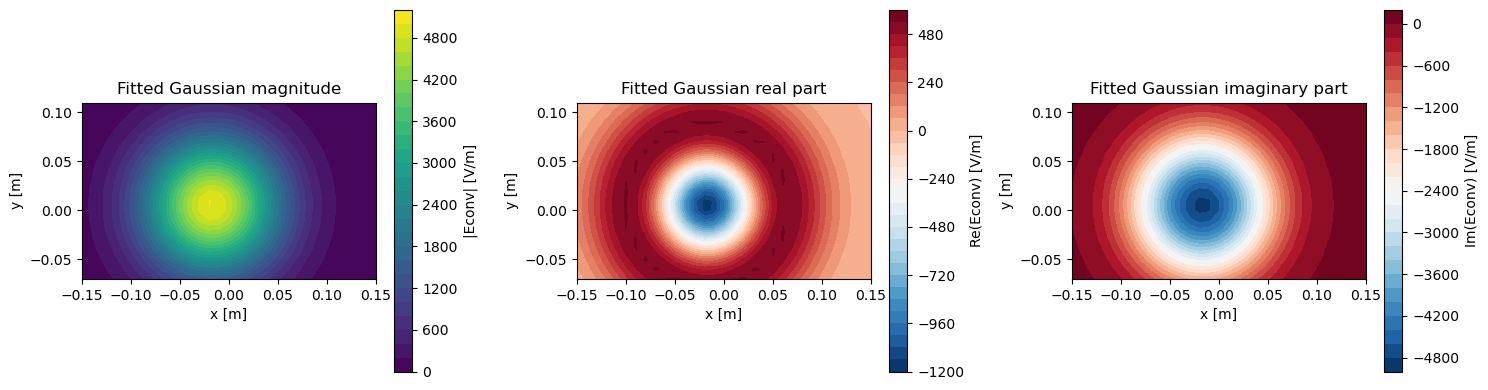

In [10]:
figure, _ = diagnostics.plot_beam_model_components(
    example,
    z_index=0,
    frequency_index=f_index,
    magnitude_title='Fitted Gaussian magnitude',
    real_title='Fitted Gaussian real part',
    imaginary_title='Fitted Gaussian imaginary part',
    x_label='x [m]',
    y_label='y [m]',
    magnitude_colorbar_label='|Econv| [V/m]',
    real_colorbar_label='Re(Econv) [V/m]',
    imaginary_colorbar_label='Im(Econv) [V/m]',
)
plots.present(figure, "gaussian_components", FIGURE_DIR / "fields")

## 8. Transverse integrals

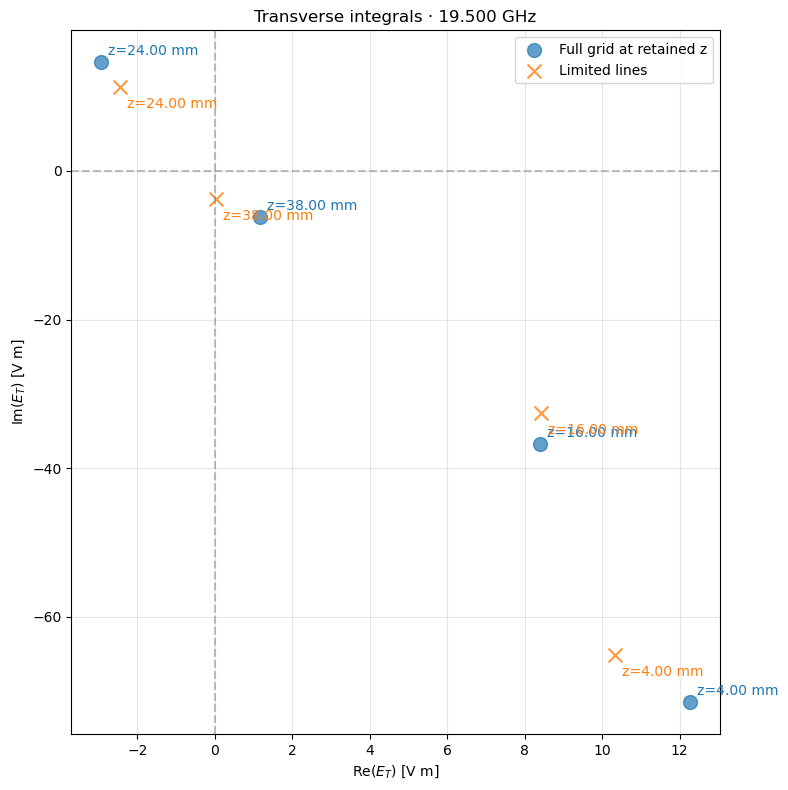

In [11]:
figure, _ = diagnostics.plot_ET_complex_plane(
    result,
    frequency_index=f_index,
    title_template='Transverse integrals · {frequency_GHz:.3f} GHz',
    x_label='$\\mathrm{Re}(E_T)$ [V m]',
    y_label='$\\mathrm{Im}(E_T)$ [V m]',
    full_label='Full grid at retained z',
    reduced_label='Limited lines',
    annotation_template='z={z_mm:.2f} mm',
)
plots.present(figure, "complex_plane", FIGURE_DIR / "integrals")

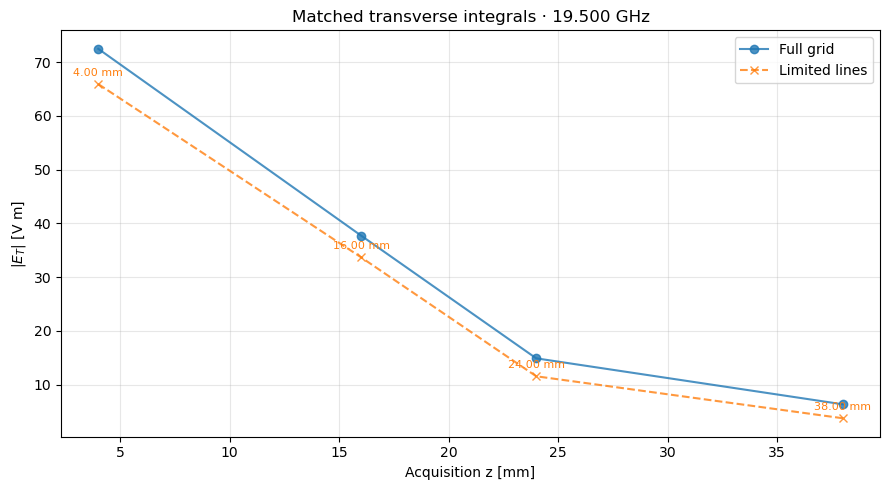

In [12]:
figure, _ = diagnostics.plot_abs_ET_over_z(
    result,
    frequency_index=f_index,
    atol=1e-09,
    title_template='Matched transverse integrals · {frequency_GHz:.3f} GHz',
    x_label='Acquisition z [mm]',
    y_label='$|E_T|$ [V m]',
    full_label='Full grid',
    reduced_label='Limited lines',
    annotation_template='{z_mm:.2f} mm',
)
plots.present(figure, "matched_z", FIGURE_DIR / "integrals")

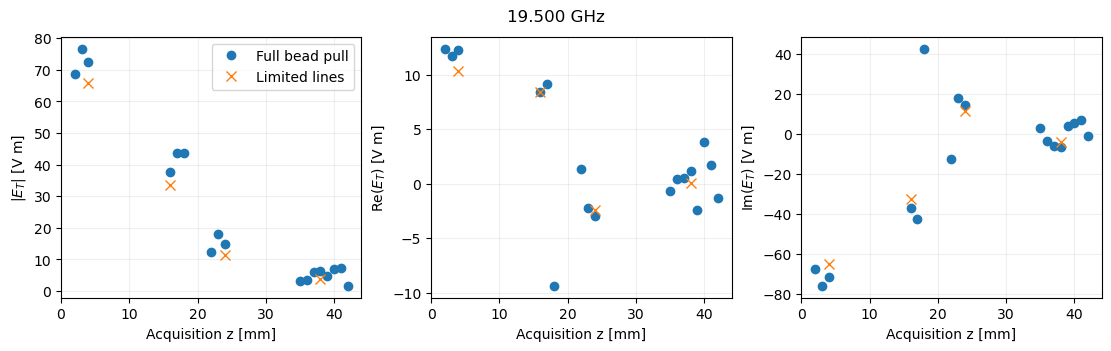

In [13]:
plots.present(
    plots.plot_integrals(
        result,
        frequency_index=f_index,
        title_template='{frequency_GHz:.3f} GHz',
        x_label='Acquisition z [mm]',
        magnitude_y_label='$|E_T|$ [V m]',
        real_y_label='$\\mathrm{Re}(E_T)$ [V m]',
        imaginary_y_label='$\\mathrm{Im}(E_T)$ [V m]',
        full_label='Full bead pull',
        reduced_label='Limited lines',
    ),
    "integrals_overview", FIGURE_DIR / "integrals",
)

## 9. Integrals across frequency

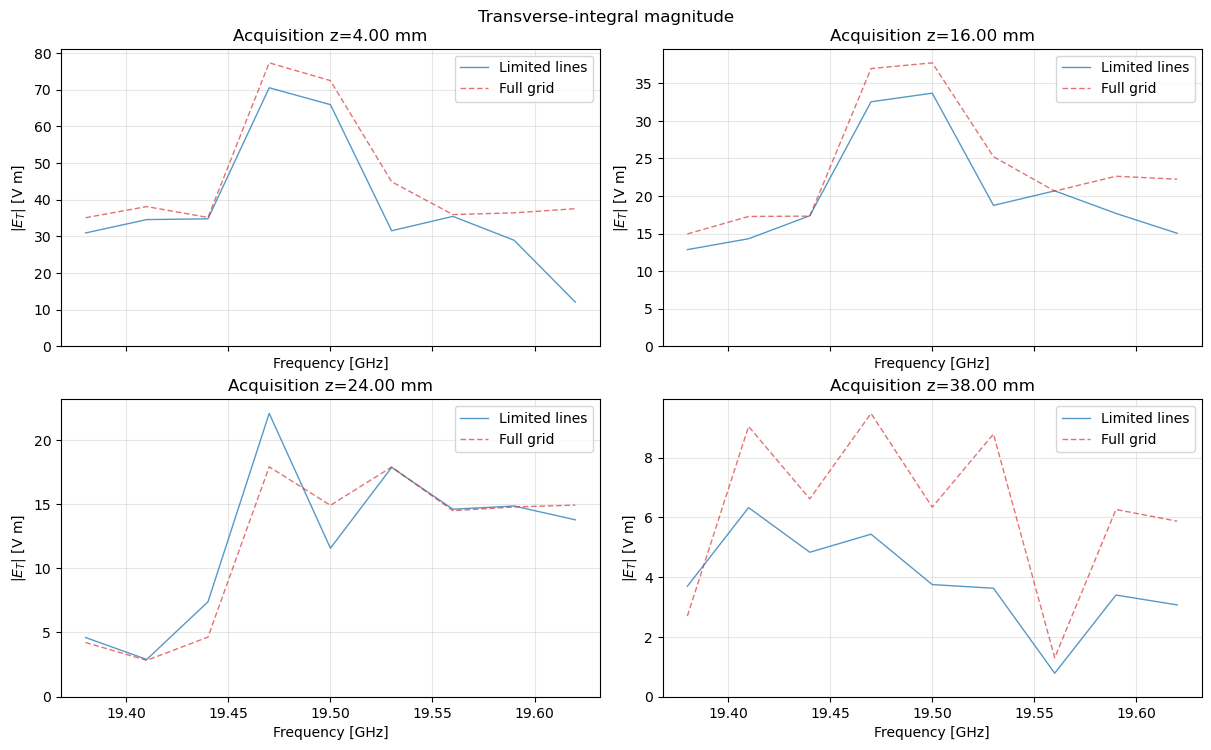

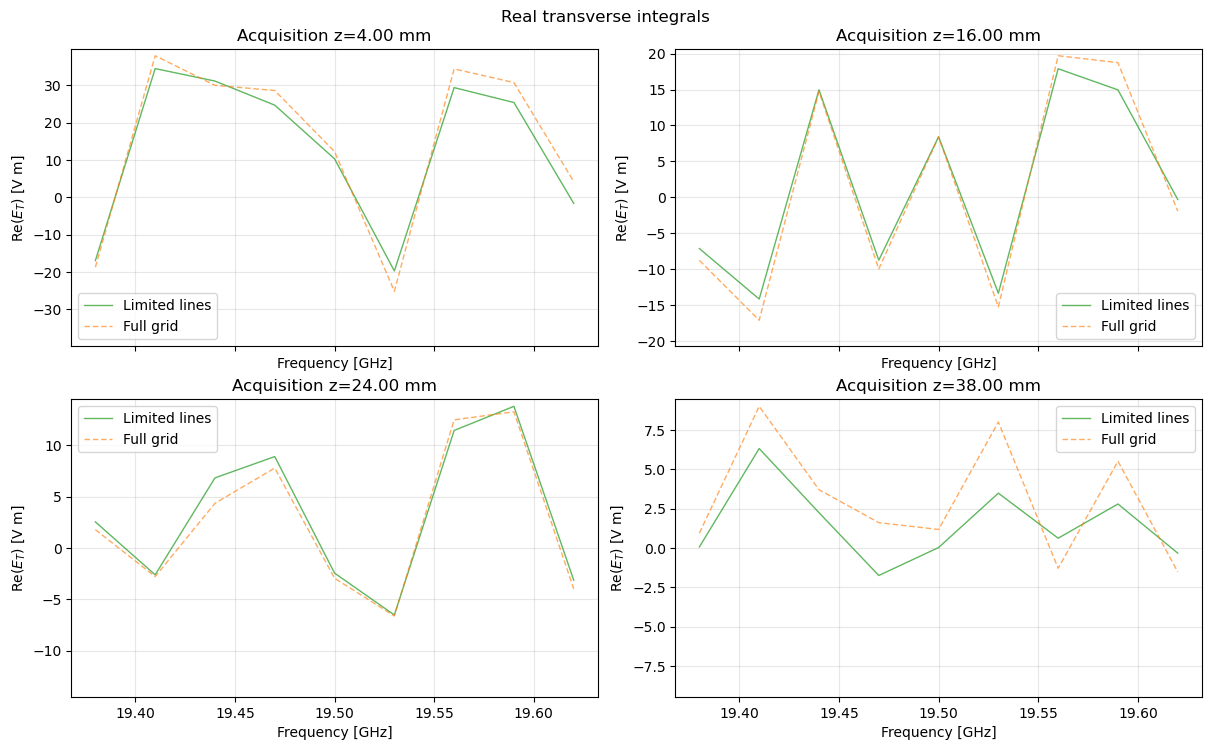

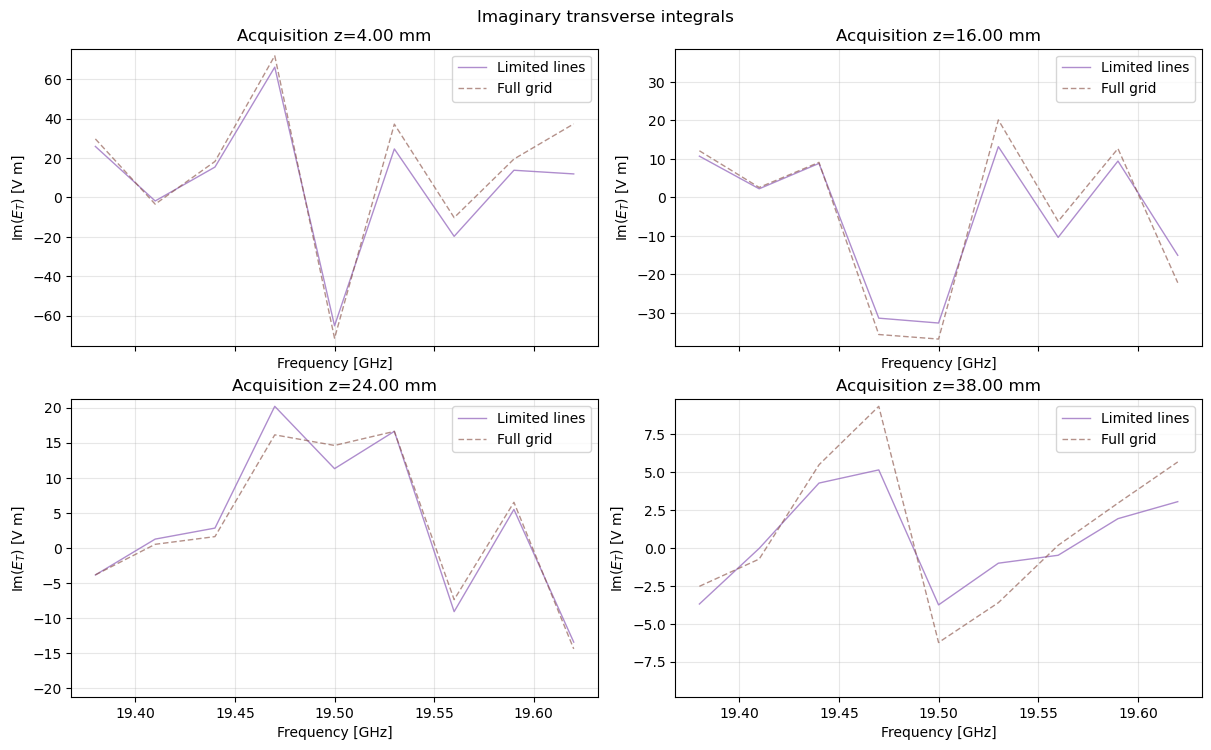

In [14]:
magnitude, real, imaginary, _ = diagnostics.plot_abs_ET_grid_over_frequency(
    result,
    atol=1e-09,
    max_et_for_scaling=500.0,
    colors=('tab:blue', 'tab:red'),
    colors_real=('tab:green', 'tab:orange'),
    colors_imag=('tab:purple', 'tab:brown'),
    x_label='Frequency [GHz]',
    magnitude_y_label='$|E_T|$ [V m]',
    real_y_label='$\\mathrm{Re}(E_T)$ [V m]',
    imaginary_y_label='$\\mathrm{Im}(E_T)$ [V m]',
    magnitude_title='Transverse-integral magnitude',
    real_title='Real transverse integrals',
    imaginary_title='Imaginary transverse integrals',
    panel_title_template='Acquisition z={z_mm:.2f} mm',
    full_label='Full grid',
    reduced_label='Limited lines',
)
for stem, (figure, _) in zip(("magnitude", "real", "imaginary"), (magnitude, real, imaginary)):
    plots.present(figure, stem, FIGURE_DIR / "integrals/frequency")

## 10. Integral error

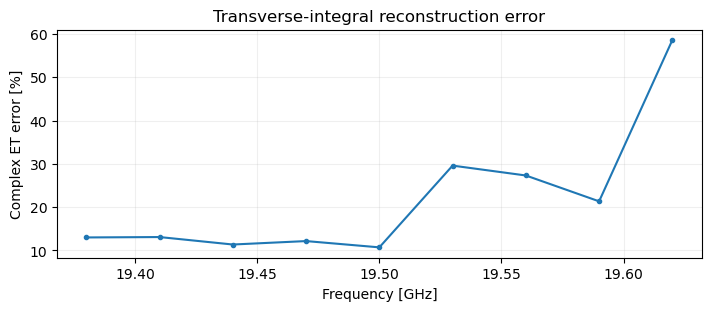

In [15]:
plots.present(
    plots.plot_integral_error(
        result,
        title='Transverse-integral reconstruction error',
        x_label='Frequency [GHz]',
        y_label='Complex ET error [%]',
    ),
    "complex_error", FIGURE_DIR / "integrals",
)

## 11. Mode checks

Illustrations only: the reconstruction fits HG00; the higher-mode weights are fixed to zero.

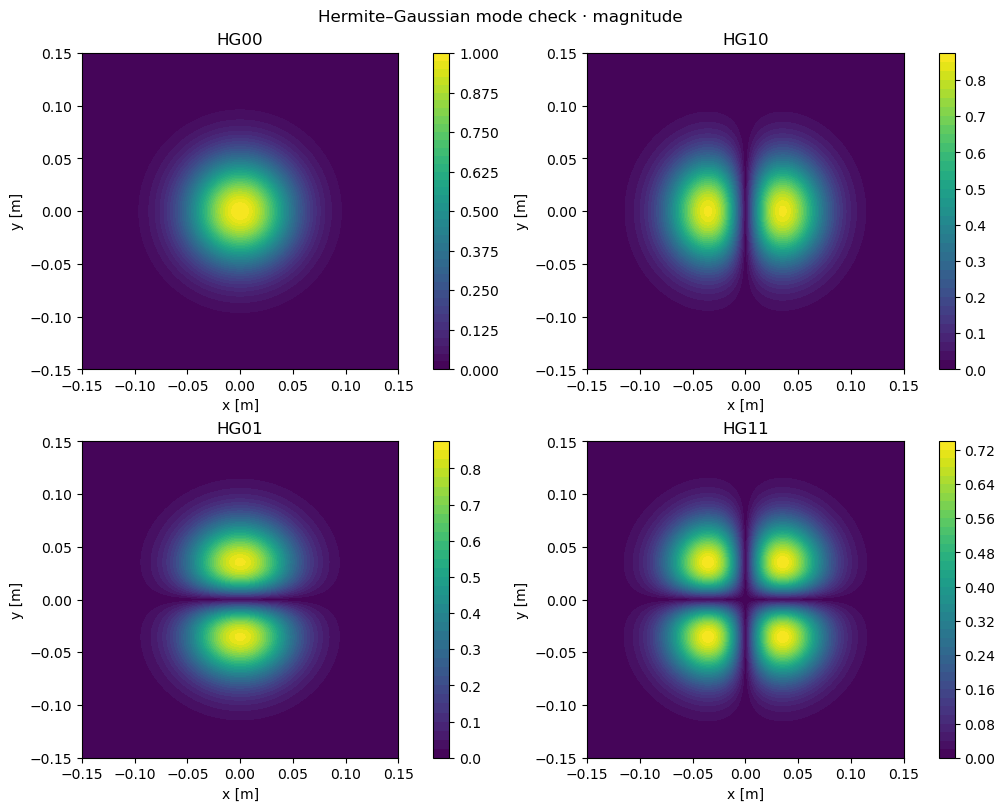

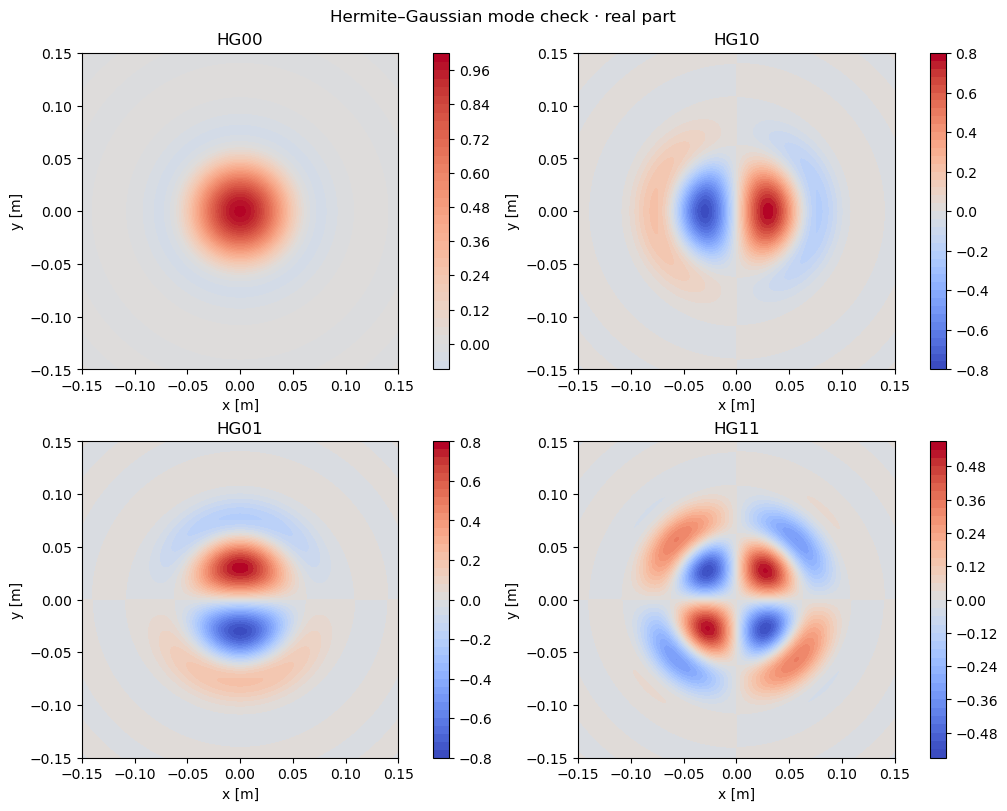

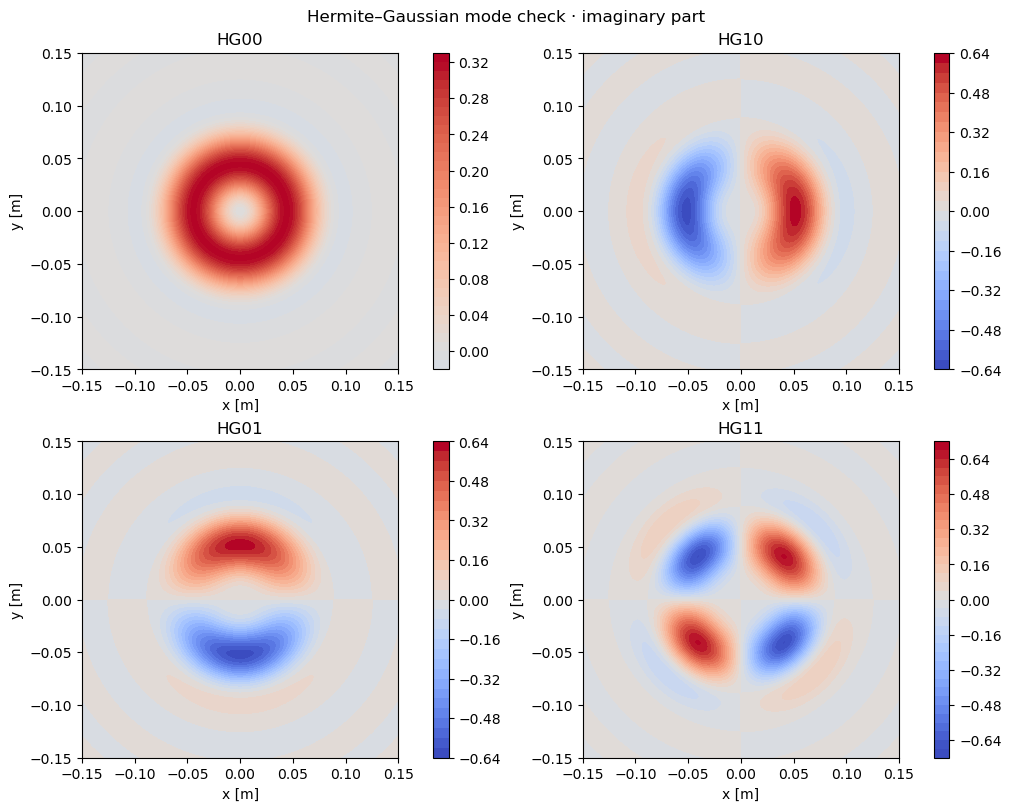

In [16]:
figures = diagnostics.create_hg_sanity_figures(
    magnitude_title='Hermite–Gaussian mode check · magnitude',
    real_title='Hermite–Gaussian mode check · real part',
    imaginary_title='Hermite–Gaussian mode check · imaginary part',
    x_label='x [m]',
    y_label='y [m]',
    mode_labels=('HG00', 'HG10', 'HG01', 'HG11'),
)
for stem, figure in zip(("magnitude", "real", "imaginary"), figures):
    plots.present(figure, stem, FIGURE_DIR / "model_checks")

## 12. Save ET data

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sbp.save_results(result, OUTPUT_DIR / "ET_results.npz")

PosixPath('outputs/sbp_verification/ET_results.npz')